# 02 · Three short calls: hedge frequency and diversification

**Objective:** extend notebook 01's accounting to short JPM, PNC and GS calls. Compare initial-only, daily, two-day and five-session hedging under independent and correlated stock-return shocks.

Each policy is evaluated on the **same paths within a dependence scenario**. Portfolio P&L is the sum of the three positions' P&Ls for each joint outcome. Portfolio tail risk is calculated from those aggregate outcomes.

The baseline uses **5,000 paths per scenario and zero stock trading costs**, isolating residual hedge risk and dependence. Notebook 03 studies costs and volatility mismatch. Initial-only means an initial delta hedge held until expiry; it is not an unhedged call position.

This completed notebook runs independently from a fresh kernel. Model inputs load from the same validated study file as notebook 00; the policy controls remain explicit. All inputs are illustrative. Paths use Q-GBM with zero dividends; the book has synthetic European calls with share-equivalent units and no exchange contract multiplier.

**Shared study inputs:** contract and scenario assumptions now load from `config/illustrative_study.json` through `load_named_inputs`. `Book` remains the validated model container. Change that file once to update the baseline across notebooks 00–03; policy/experiment controls stay explicit in each notebook. 


| Step | Purpose | Main functions/tools |
|---|---|---|
| 1–2 | Inspect named inputs and opening exposures | Dictionaries, `Book`, `initial_exposures` |
| 3 | Generate independent and correlated paths | `simulate_paths` |
| 4 | Evaluate all four hedge policies on each path set | `hedge`, `summarize` |
| 5 | Verify the aggregate cash account | Grouped audit ledger and NumPy assertions |
| 6 | Compare risk, turnover and outcome distributions | Tables, bar charts, histograms |
| 7 | Explain portfolio variance and P&L dependence | Covariance and correlation matrices |
| 8 | Attribute portfolio-tail losses to each name | Common portfolio-tail observations |
| 9–10 | Interpret the comparisons and record the run | Calculated ratios, `provenance` |

Cash attribution across names sums to one shared account because borrowing and lending use the same constant rate and there are no margin constraints. The code below checks the resulting accounting identities for every scenario/policy combination.

## 1 · Connect to the project

Find the project root, then import the same pricing and accounting helpers used in notebooks 00 and 01. Either the project root or notebook folder can be the kernel's starting directory.

In [1]:
from pathlib import Path
from hashlib import sha256
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "hedging_harness" / "core.py").is_file():
    ROOT = ROOT.parent
assert (ROOT / "hedging_harness" / "core.py").is_file(), f"Wrong project root: {ROOT}"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from hedging_harness import Book, simulate_paths, hedge, summarize, initial_exposures, provenance

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.2,
})
print(f"Project root: {ROOT}")

Project root: /Users/saireddivari/MonteCarloEvaluations


## 2 · Define the named portfolio and policies

Each security owns its contract and pricing inputs. The scenario owns the path volatilities and named correlation pairs. `notional / spot` gives each short-call quantity, and sessions divided by sessions per year gives maturity in years.

`POLICIES` maps policy names to rebalance intervals. All policies open an initial delta hedge and liquidate stock at expiry. `COST_BPS = 0.0` is the baseline here; if changed, the reported net P&L automatically includes those costs.

`AUDIT_PATH` retains one full path's per-name accounting for each of the eight cases. Every simulated outcome contributes to the distribution statistics.

In [2]:
from hedging_harness.study import load_named_inputs
option_portfolio, scenario, shared_config = load_named_inputs(
    ROOT / "config" / "illustrative_study.json"
)


POLICIES = {"initial_only": None, "daily": 1, "two_day": 2, "weekly": 5}
COST_BPS = 0.0
AUDIT_PATH = 0
N_PATHS = shared_config["n_paths"]
SEED = shared_config["seed"]


In [3]:
option_underlyings = list(option_portfolio)
assert set(scenario["path_vols"]) == set(option_underlyings)
assert isinstance(N_PATHS, int) and N_PATHS >= 2
assert isinstance(AUDIT_PATH, int) and 0 <= AUDIT_PATH < N_PATHS
assert np.isfinite(COST_BPS) and COST_BPS >= 0

assumptions = pd.DataFrame.from_dict(option_portfolio, orient="index")
assumptions.index.name = "name"
for field in ("days_to_expiration", "days_in_trading_year", "risk_free_rate"):
    assert assumptions[field].nunique() == 1, f"The simulator requires one common {field}."
assumptions["call_units"] = assumptions["notional"] / assumptions["spot"]
assumptions["maturity_years"] = assumptions["days_to_expiration"] / assumptions["days_in_trading_year"]
assumptions["path_vol"] = pd.Series(scenario["path_vols"])
assert not assumptions.isna().any().any()

correlation_matrix = pd.DataFrame(
    np.eye(len(option_underlyings)), index=option_underlyings, columns=option_underlyings
)
seen_pairs = set()
for (name_a, name_b), value in scenario["correlations"].items():
    assert name_a in option_portfolio and name_b in option_portfolio and name_a != name_b
    assert np.isfinite(value) and -1 <= value <= 1
    pair = frozenset((name_a, name_b))
    assert pair not in seen_pairs, "Specify each unordered correlation pair once."
    seen_pairs.add(pair)
    correlation_matrix.loc[name_a, name_b] = value
    correlation_matrix.loc[name_b, name_a] = value
assert len(seen_pairs) == len(option_underlyings) * (len(option_underlyings) - 1) // 2
assert np.linalg.eigvalsh(correlation_matrix.to_numpy()).min() >= -1e-10

first_option = option_portfolio[option_underlyings[0]]
book = Book(
    names=tuple(option_underlyings),
    spots=tuple(option_portfolio[name]["spot"] for name in option_underlyings),
    strikes=tuple(option_portfolio[name]["strike"] for name in option_underlyings),
    notionals=tuple(option_portfolio[name]["notional"] for name in option_underlyings),
    pricing_vols=tuple(option_portfolio[name]["pricing_vol"] for name in option_underlyings),
    steps=first_option["days_to_expiration"],
    sessions_per_year=first_option["days_in_trading_year"],
    rate=first_option["risk_free_rate"],
)
path_vols = [scenario["path_vols"][name] for name in option_underlyings]
opening_exposures = initial_exposures(book)
print("Named study assumptions:")
display(assumptions)
print("Opening short-call exposures and delta-offsetting stock quantities:")
display(opening_exposures.round(4))
print(f"Total initial underlying notional: ${sum(book.notionals):,.0f}")
print("Equal notional does not imply equal option premium, gamma or vega.")

Named study assumptions:


,spot,strike,notional,pricing_vol,days_to_expiration,days_in_trading_year,risk_free_rate,call_units,maturity_years,path_vol
name,,,,,,,,,,
JPM,100.0,100.0,100000.0,0.22,63,252,0.04,1000.0,0.25,0.22
PNC,100.0,100.0,100000.0,0.28,63,252,0.04,1000.0,0.25,0.28
GS,100.0,100.0,100000.0,0.26,63,252,0.04,1000.0,0.25,0.26


Opening short-call exposures and delta-offsetting stock quantities:


,short_call_units,initial_premium,hedge_shares,option_dollar_delta,option_gamma_pnl_for_1pct_move,option_vega_per_vol_point
name,,,,,,
JPM,1000.0,4879.8441,558.0034,-55800.3423,-17.9417,-197.3591
PNC,1000.0,6064.5144,556.2343,-55623.4308,-14.1062,-197.4862
GS,1000.0,5669.5521,556.4296,-55642.9617,-15.1902,-197.4723


Total initial underlying notional: $300,000
Equal notional does not imply equal option premium, gamma or vega.


## 3 · Generate independent and correlated outcomes

The two scenarios keep the same spots, strikes, rates, path volatilities, pricing volatilities and random seed. Only the stock-shock correlation changes:

- **independent:** identity correlation matrix.
- **illustrative_correlated:** the configured named-pair matrix, matching notebook 00.

Each scenario uses one path set for every hedge policy. Across dependence scenarios, the same underlying normal draws are transformed differently, so the resulting price paths differ. Finite-sample marginal results may change; standalone option fair values do not change when their own pricing inputs stay fixed.

The empirical correlation check uses one-session **log returns**, pooling independent path/session increments. Price-level correlation would be a different diagnostic.

In [4]:
dependence = {
    "independent": np.eye(len(book.names)),
    "illustrative_correlated": correlation_matrix.loc[option_underlyings, option_underlyings].to_numpy(),
}
path_sets = {}
return_correlations = {}
for label, correlation in dependence.items():
    paths = simulate_paths(book, path_vols, correlation, n_paths=N_PATHS, seed=SEED)
    assert paths.shape == (N_PATHS, book.steps + 1, len(book.names))
    assert np.isfinite(paths).all() and (paths > 0).all()
    np.testing.assert_allclose(paths[:, 0, :], np.broadcast_to(book.spots, (N_PATHS, len(book.names))))
    path_sets[label] = paths
    returns = np.diff(np.log(paths), axis=1).reshape(-1, len(book.names))
    return_correlations[label] = pd.DataFrame(
        np.corrcoef(returns, rowvar=False), index=book.names, columns=book.names
    )
    print(f"{label}: {paths.shape}; empirical return correlations:")
    display(return_correlations[label].round(4))

independent: (5000, 64, 3); empirical return correlations:


,JPM,PNC,GS
JPM,1.0000,0.0004,0.0011
PNC,0.0004,1.0000,-0.0011
GS,0.0011,-0.0011,1.0000


illustrative_correlated: (5000, 64, 3); empirical return correlations:


,JPM,PNC,GS
JPM,1.0000,0.6503,0.7003
PNC,0.6503,1.0000,0.5493
GS,0.7003,0.5493,1.0000


## 4 · Apply all four policies to each path set

For each scenario, `hedge(...)` runs every policy on the same realized stock histories. Its output contains one terminal P&L per outcome and per name. Sum across names **within each outcome** to obtain the joint portfolio result, then compute portfolio statistics.

`summarize(...)` reports means, Monte Carlo mean SEs, P&L standard deviation, RMSE, fifth-percentile P&L, expected shortfall, costs and turnover. ES95 is minus the mean of the worst 5% of outcomes, rounded up to a whole count. It can be negative when even that tail is profitable.

With matched pricing/path volatilities and zero costs, predictable stock hedging has zero expected discounted gain under Q. The comparison concerns residual risk and trading activity; sample mean differences are not evidence of alpha.

In [5]:
results = {}
tables = []
for label, paths in path_sets.items():
    for policy, interval in POLICIES.items():
        result = hedge(
            book, paths, hedge_every=interval, cost_bps=COST_BPS, audit_path=AUDIT_PATH
        )
        results[label, policy] = result
        table = summarize(result).reset_index().assign(dependence=label, policy=policy)
        tables.append(table)
        total_pnl = result.terminal_pnl.sum(axis=1)
        portfolio_row = table.loc[table["name"].eq("Portfolio")].iloc[0]
        np.testing.assert_allclose(portfolio_row["mean_pnl"], total_pnl.mean(), atol=1e-9)
        np.testing.assert_allclose(portfolio_row["pnl_std"], total_pnl.std(ddof=1), rtol=1e-12)

summary = pd.concat(tables, ignore_index=True)
portfolio = summary.loc[summary["name"].eq("Portfolio")].copy()
portfolio_table = portfolio.set_index(["dependence", "policy"])
display(portfolio_table[[
    "paths", "mean_pnl", "mean_se", "pnl_std", "pnl_p05", "loss_es95", "mean_turnover"
]].round(4))
print(f"Completed {len(results)} scenario/policy cases on {N_PATHS:,} outcomes each.")

paths  mean_pnl   mean_se    pnl_std  \
dependence              policy                                               
independent             initial_only   5000   69.1846   93.7637  6630.0971   
                        daily          5000   13.5047   13.4584   951.6542   
                        two_day        5000   20.7080   18.5721  1313.2471   
                        weekly         5000  -24.1644   29.0562  2054.5808   
illustrative_correlated initial_only   5000   59.9627  123.5524  8736.4710   
                        daily          5000    3.4253   17.0230  1203.7099   
                        two_day        5000   -4.2497   23.5055  1662.0904   
                        weekly         5000  -42.7499   36.2595  2563.9360   

                                         pnl_p05   loss_es95  mean_turnover  
dependence              policy                                               
independent             initial_only -11867.2903  15719.4041   3.359820e+05  
                        daily         -1576.3855   2069.6599   1.083514e+06  
                        two_day       -2196.6714   2850.6431   8.691445e+05  
                        weekly        -3485.0242   4628.9670   6.687573e+05  
illustrative_correlated initial_only -16992.0891  23544.9116   3.360583e+05  
                        daily         -2005.2126   2692.1777   1.083990e+06  
                        two_day       -2808.9867   3832.9448   8.700879e+05  
                        weekly        -4303.8947   5995.6968   6.700091e+05

Completed 8 scenario/policy cases on 5,000 outcomes each.


## 5 · Verify the shared-account aggregation

Each name has its own attributed cash balance, but all use the same linear financing rate. Summing those balances therefore gives the shared cash account. Stock holdings remain distinct because JPM shares and PNC shares are different assets.

For the audited outcome in **every** scenario/policy case, sum the cash flows across names at each date. The aggregate account must satisfy

$$\Delta C = \text{premium}+\text{interest}+\text{stock cash flow}-\text{cost}-\text{payoff paid}.$$

Marked portfolio value is cash plus stock value minus option liabilities. At expiry, all shares and liabilities must be zero, and final shared cash must equal the sum of the three terminal P&Ls. The tables below display the correlated five-session case as an example; assertions cover all eight cases.

In [6]:
account_columns = [
    "premium_received", "interest", "stock_cashflow", "transaction_cost", "payoff_paid",
    "cash", "stock_value", "option_liability", "net_value",
]
aggregate_ledgers = {}
accounting_rows = []
for (label, policy), result in results.items():
    ledger = result.ledger
    assert len(ledger) == (book.steps + 1) * len(book.names)
    aggregate = ledger.groupby("step")[account_columns].sum()
    aggregate_ledgers[label, policy] = aggregate
    cash_flows = (
        aggregate["premium_received"] + aggregate["interest"] + aggregate["stock_cashflow"]
        - aggregate["transaction_cost"] - aggregate["payoff_paid"]
    )
    cash_residual = aggregate["cash"] - cash_flows.cumsum()
    value_residual = aggregate["net_value"] - (
        aggregate["cash"] + aggregate["stock_value"] - aggregate["option_liability"]
    )
    np.testing.assert_allclose(cash_residual, 0.0, atol=1e-8, rtol=0)
    np.testing.assert_allclose(value_residual, 0.0, atol=1e-8, rtol=0)
    last_rows = ledger.loc[ledger["step"].eq(book.steps)]
    assert last_rows["shares_after"].eq(0).all()
    assert last_rows["option_liability"].eq(0).all()
    np.testing.assert_allclose(
        aggregate.iloc[-1]["cash"], result.terminal_pnl[AUDIT_PATH].sum(), atol=1e-8, rtol=0
    )
    accounting_rows.append({
        "dependence": label, "policy": policy,
        "max_cash_residual": cash_residual.abs().max(),
        "max_value_residual": value_residual.abs().max(),
        "terminal_shared_cash": aggregate.iloc[-1]["cash"],
    })
accounting_checks = pd.DataFrame(accounting_rows).set_index(["dependence", "policy"])
display(accounting_checks.round(8))
example_ledger = aggregate_ledgers["illustrative_correlated", "weekly"]
selected_steps = sorted({0, 1, 4, 5, 6, max(0, book.steps - 1), book.steps})
print("Correlated five-session hedge: shared-account cash flows and cash:")
display(example_ledger.loc[example_ledger.index.isin(selected_steps), [
    "premium_received", "interest", "stock_cashflow", "transaction_cost", "payoff_paid", "cash"
]].round(4))
print("All shared-account cash, marked-value and terminal-settlement checks passed.")

max_cash_residual  max_value_residual  \
dependence              policy                                                
independent             initial_only                0.0                 0.0   
                        daily                       0.0                 0.0   
                        two_day                     0.0                 0.0   
                        weekly                      0.0                 0.0   
illustrative_correlated initial_only                0.0                 0.0   
                        daily                       0.0                 0.0   
                        two_day                     0.0                 0.0   
                        weekly                      0.0                 0.0   

                                      terminal_shared_cash  
dependence              policy                              
independent             initial_only          -1083.734314  
                        daily                 -1247.211926  
                        two_day               -1118.013023  
                        weekly                -3008.028700  
illustrative_correlated initial_only           3449.385729  
                        daily                 -1057.808273  
                        two_day               -1026.760055  
                        weekly                 -348.361669

Correlated five-session hedge: shared-account cash flows and cash:


,premium_received,interest,stock_cashflow,transaction_cost,payoff_paid,cash
step,,,,,,
0,16613.9107,0.0000,-167066.7347,0.0,0.0000,-150452.8240
1,0.0000,-23.8833,-0.0000,0.0,0.0000,-150476.7073
4,0.0000,-23.8947,-0.0000,0.0,0.0000,-150548.3800
5,0.0000,-23.8985,-2503.9855,0.0,0.0000,-153076.2640
6,0.0000,-24.2997,-0.0000,0.0,0.0000,-153100.5637
62,0.0000,-41.4456,-0.0000,0.0,0.0000,-261128.1085
63,0.0000,-41.4522,284499.3328,0.0,23678.1338,-348.3617


All shared-account cash, marked-value and terminal-settlement checks passed.


## 6 · Compare hedge frequency, risk and turnover

The risk table compares each policy's P&L standard deviation with both the daily hedge and the initial-only hedge. A ratio above one in `std_relative_to_daily` means more residual variability than daily hedging in that scenario. `std_reduction_vs_initial_pct` measures the percentage reduction relative to initial-only.

The charts compare P&L standard deviation, portfolio ES95 and total dollar turnover. Lower variability can require more trading. With the zero-cost baseline, turnover is an activity measure; costs are not yet used to select a policy.

P&L standard deviation describes simulated economic variability. Mean SE measures uncertainty in the estimated mean and should not be substituted for that risk measure.

pnl_std  std_relative_to_daily  \
dependence              policy                                           
independent             initial_only  6630.0971                 6.9669   
                        daily          951.6542                 1.0000   
                        two_day       1313.2471                 1.3800   
                        weekly        2054.5808                 2.1590   
illustrative_correlated initial_only  8736.4710                 7.2580   
                        daily         1203.7099                 1.0000   
                        two_day       1662.0904                 1.3808   
                        weekly        2563.9360                 2.1300   

                                      std_reduction_vs_initial_pct  \
dependence              policy                                       
independent             initial_only                        0.0000   
                        daily                              85.6465   
                        two_day                            80.1926   
                        weekly                             69.0113   
illustrative_correlated initial_only                        0.0000   
                        daily                              86.2220   
                        two_day                            80.9753   
                        weekly                             70.6525   

                                       loss_es95  mean_turnover  
dependence              policy                                   
independent             initial_only  15719.4041   3.359820e+05  
                        daily          2069.6599   1.083514e+06  
                        two_day        2850.6431   8.691445e+05  
                        weekly         4628.9670   6.687573e+05  
illustrative_correlated initial_only  23544.9116   3.360583e+05  
                        daily          2692.1777   1.083990e+06  
                        two_day        3832.9448   8.700879e+05  
                        weekly         5995.6968   6.700091e+05

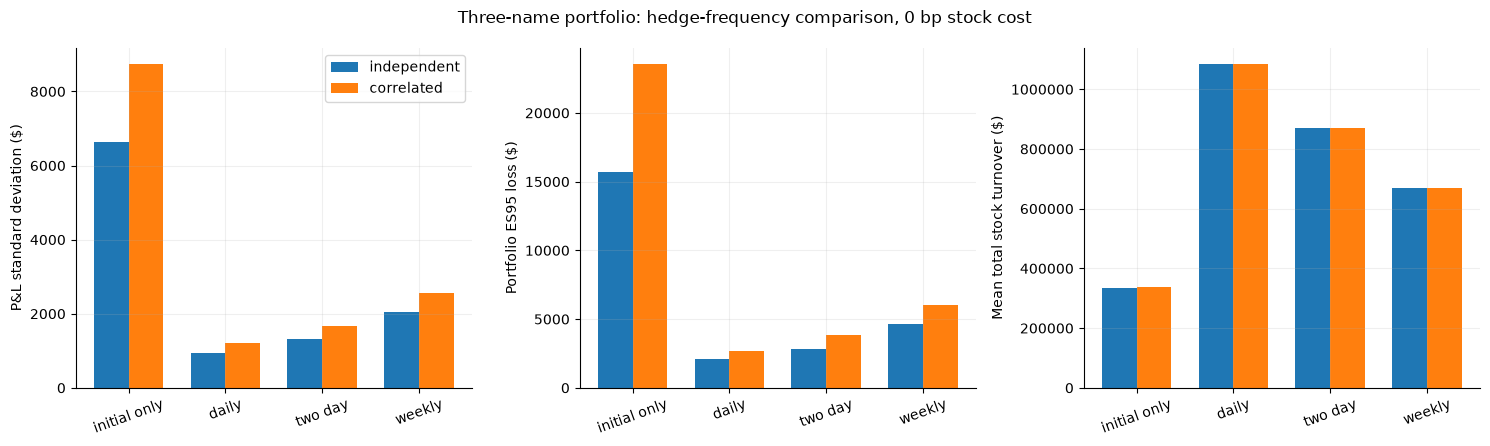

In [7]:
risk_rows = []
for label in dependence:
    daily_std = portfolio_table.loc[(label, "daily"), "pnl_std"]
    initial_std = portfolio_table.loc[(label, "initial_only"), "pnl_std"]
    for policy in POLICIES:
        row = portfolio_table.loc[(label, policy)]
        risk_rows.append({
            "dependence": label, "policy": policy,
            "pnl_std": row["pnl_std"],
            "std_relative_to_daily": row["pnl_std"] / daily_std if daily_std else np.nan,
            "std_reduction_vs_initial_pct": 100 * (1 - row["pnl_std"] / initial_std) if initial_std else np.nan,
            "loss_es95": row["loss_es95"],
            "mean_turnover": row["mean_turnover"],
        })
risk_comparison = pd.DataFrame(risk_rows).set_index(["dependence", "policy"])
display(risk_comparison.round(4))

policy_names = list(POLICIES)
positions = np.arange(len(policy_names))
width = 0.36
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
metrics = [("pnl_std", "P&L standard deviation ($)"), ("loss_es95", "Portfolio ES95 loss ($)"), ("mean_turnover", "Mean total stock turnover ($)")]
for ax, (metric, ylabel) in zip(axes, metrics):
    for scenario_index, label in enumerate(dependence):
        heights = portfolio_table.loc[label].reindex(policy_names)[metric].to_numpy()
        offset = (scenario_index - 0.5) * width
        ax.bar(positions + offset, heights, width=width, label=label.replace("illustrative_", ""))
    ax.set_xticks(positions, [p.replace("_", " ") for p in policy_names], rotation=20)
    ax.set_ylabel(ylabel)
    ax.ticklabel_format(axis="y", style="plain")
axes[0].legend()
fig.suptitle(f"Three-name portfolio: hedge-frequency comparison, {COST_BPS:g} bp stock cost")
fig.tight_layout()
plt.show()

### Compare the aggregate distributions

The next figure overlays daily and five-session portfolio P&L distributions in each dependence scenario. The panels use a common P&L axis and common histogram bins, making their spread and tails comparable.

The name-level table underneath shows daily results in the correlated scenario. The portfolio row is computed from joint summed P&L, not from a sum of name-level standard deviations or tail statistics.

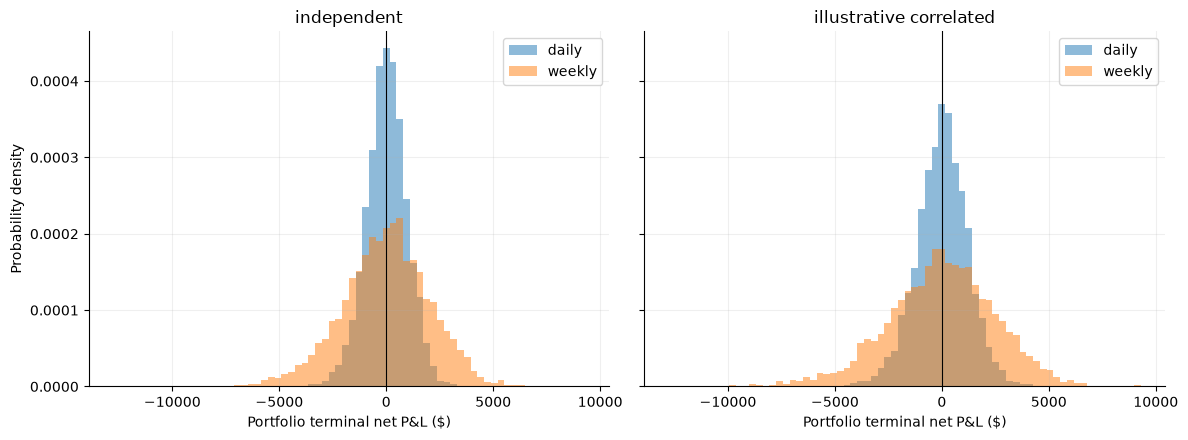

Correlated scenario, daily hedge: names and joint portfolio:


,mean_pnl,mean_se,pnl_std,loss_es95
name,,,,
JPM,-0.5853,6.8163,481.9820,1135.0853
PNC,4.9731,8.6824,613.9410,1438.0934
GS,-0.9625,8.1100,573.4611,1296.1798
Portfolio,3.4253,17.0230,1203.7099,2692.1777


In [8]:
plotted_policies = ["daily", "weekly"]
plotted_pnls = [
    results[label, policy].terminal_pnl.sum(axis=1)
    for label in dependence for policy in plotted_policies
]
bins = np.histogram_bin_edges(np.concatenate(plotted_pnls), bins=70)
fig, axes = plt.subplots(1, len(dependence), figsize=(12, 4.5), sharex=True, sharey=True)
for ax, label in zip(axes, dependence):
    for policy in plotted_policies:
        pnl = results[label, policy].terminal_pnl.sum(axis=1)
        ax.hist(pnl, bins=bins, alpha=0.5, density=True, label=policy)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set(title=label.replace("_", " "), xlabel="Portfolio terminal net P&L ($)")
    ax.legend()
axes[0].set_ylabel("Probability density")
fig.tight_layout()
plt.show()
print("Correlated scenario, daily hedge: names and joint portfolio:")
display(summary.loc[
    summary["dependence"].eq("illustrative_correlated") & summary["policy"].eq("daily"),
    ["name", "mean_pnl", "mean_se", "pnl_std", "loss_es95"],
].set_index("name").round(4))

## 7 · Explain portfolio variance and P&L correlations

For position P&Ls $X_i$,

$$\operatorname{Var}\!\left(\sum_i X_i\right)
=\sum_i\operatorname{Var}(X_i)+2\sum_{i<j}\operatorname{Cov}(X_i,X_j).$$

`own_variances` is the covariance matrix's trace. `cross_covariances` is the sum of its off-diagonal entries, which already includes both occurrences of every pair. Their sum must match the variance of the pathwise aggregate portfolio P&L.

`std_diversification_ratio` compares portfolio standard deviation with the sum of standalone standard deviations. Values below one indicate diversification under that measure. This is an accounting decomposition of simulated outcomes, rather than a causal allocation of business risks.

Stock-return correlation and hedge-error P&L correlation are different quantities. Discrete hedge errors depend nonlinearly on the paths, so their correlations need not match the configured shock correlations. Even independent simulations have small sample covariance rather than exactly zero covariance.

In [9]:
variance_rows = []
covariances = {}
pnl_correlations = {}
for (label, policy), result in results.items():
    pnl = result.terminal_pnl
    covariance = np.cov(pnl, rowvar=False, ddof=1)
    covariances[label, policy] = pd.DataFrame(covariance, index=book.names, columns=book.names)
    pnl_correlations[label, policy] = pd.DataFrame(
        np.corrcoef(pnl, rowvar=False), index=book.names, columns=book.names
    )
    own = np.trace(covariance)
    cross = covariance.sum() - own
    observed = pnl.sum(axis=1).var(ddof=1)
    np.testing.assert_allclose(own + cross, observed, rtol=1e-12, atol=1e-8)
    sum_standalone_stds = np.sqrt(np.diag(covariance)).sum()
    variance_rows.append({
        "dependence": label, "policy": policy,
        "own_variances": own, "cross_covariances": cross,
        "portfolio_variance": observed,
        "std_diversification_ratio": np.sqrt(observed) / sum_standalone_stds if sum_standalone_stds else np.nan,
    })
variance_decomposition = pd.DataFrame(variance_rows).set_index(["dependence", "policy"])
display(variance_decomposition.round(4))
for label in dependence:
    print(f"{label}: daily-hedge P&L correlations:")
    display(pnl_correlations[label, "daily"].round(4))
print("Variance identities passed for every scenario/policy case.")

own_variances  cross_covariances  \
dependence              policy                                           
independent             initial_only   4.411386e+07      -1.556735e+05   
                        daily          9.311325e+05      -2.548690e+04   
                        two_day        1.748864e+06      -2.424635e+04   
                        weekly         4.247768e+06      -2.646606e+04   
illustrative_correlated initial_only   4.426160e+07       3.206432e+07   
                        daily          9.380878e+05       5.108298e+05   
                        two_day        1.745811e+06       1.016734e+06   
                        weekly         4.181737e+06       2.392031e+06   

                                      portfolio_variance  \
dependence              policy                             
independent             initial_only        4.395819e+07   
                        daily               9.056456e+05   
                        two_day             1.724618e+06   
                        weekly              4.221302e+06   
illustrative_correlated initial_only        7.632593e+07   
                        daily               1.448918e+06   
                        two_day             2.762545e+06   
                        weekly              6.573768e+06   

                                      std_diversification_ratio  
dependence              policy                                   
independent             initial_only                     0.5791  
                        daily                            0.5722  
                        two_day                          0.5758  
                        weekly                           0.5782  
illustrative_correlated initial_only                     0.7614  
                        daily                            0.7211  
                        two_day                          0.7294  
                        weekly                           0.7276

independent: daily-hedge P&L correlations:


,JPM,PNC,GS
JPM,1.0000,-0.0361,-0.0003
PNC,-0.0361,1.0000,-0.0059
GS,-0.0003,-0.0059,1.0000


illustrative_correlated: daily-hedge P&L correlations:


,JPM,PNC,GS
JPM,1.0000,0.2918,0.3551
PNC,0.2918,1.0000,0.2015
GS,0.3551,0.2015,1.0000


Variance identities passed for every scenario/policy case.


## 8 · Attribute the portfolio's worst outcomes

Select the worst 5% of **portfolio** outcomes, then calculate each name's average loss on those same observations. These contributions sum to the portfolio ES95. They answer which name contributes most when the combined book experiences its worst outcomes.

A standalone name's ES95 selects that name's own worst observations, which may occur on different paths. Adding those standalone ES95 values therefore does not calculate portfolio ES95. The comparison table reports their sum alongside the actual portfolio statistic to make the distinction explicit.

Contributions can be negative if a name offsets losses in the selected portfolio tail. Percentage contributions can exceed 100% when another name offsets losses. These are descriptive sample allocations and do not quantify tail-estimation uncertainty.

In [10]:
tail_count = max(1, int(np.ceil(0.05 * N_PATHS)))
tail_rows = []
tail_comparison_rows = []
for (label, policy), result in results.items():
    pnl = result.terminal_pnl
    portfolio_pnl = pnl.sum(axis=1)
    tail_indices = np.argsort(portfolio_pnl)[:tail_count]
    contributions = -pnl[tail_indices].mean(axis=0)
    portfolio_es95 = -portfolio_pnl[tail_indices].mean()
    case_summary = summary.loc[
        summary["dependence"].eq(label) & summary["policy"].eq(policy)
    ].set_index("name")
    np.testing.assert_allclose(contributions.sum(), portfolio_es95, atol=1e-8, rtol=1e-12)
    np.testing.assert_allclose(portfolio_es95, case_summary.loc["Portfolio", "loss_es95"], atol=1e-8)
    for name, contribution in zip(book.names, contributions):
        tail_rows.append({
            "dependence": label, "policy": policy, "name": name,
            "standalone_name_ES95": case_summary.loc[name, "loss_es95"],
            "portfolio_tail_loss_contribution": contribution,
            "portfolio_tail_contribution_pct": 100 * contribution / portfolio_es95 if portfolio_es95 else np.nan,
        })
    standalone_sum = case_summary.loc[list(book.names), "loss_es95"].sum()
    tail_comparison_rows.append({
        "dependence": label, "policy": policy,
        "sum_standalone_ES95": standalone_sum,
        "actual_portfolio_ES95": portfolio_es95,
        "standalone_sum_minus_portfolio": standalone_sum - portfolio_es95,
    })
tail_contributions = pd.DataFrame(tail_rows).set_index(["dependence", "policy", "name"])
tail_comparison = pd.DataFrame(tail_comparison_rows).set_index(["dependence", "policy"])
print(f"Portfolio tail contains {tail_count} of {N_PATHS} outcomes per case.")
display(tail_comparison.round(4))
print("Name contributions in the daily and five-session portfolio tails:")
display(tail_contributions.loc[
    tail_contributions.index.get_level_values("policy").isin(["daily", "weekly"])
].round(4))
print("Tail-contribution sums agree with portfolio ES95 in all cases.")

Portfolio tail contains 250 of 5000 outcomes per case.


sum_standalone_ES95  \
dependence              policy                              
independent             initial_only           29379.9832   
                        daily                   3812.0782   
                        two_day                 5206.4921   
                        weekly                  8362.4854   
illustrative_correlated initial_only           29531.0826   
                        daily                   3869.3584   
                        two_day                 5343.9261   
                        weekly                  8277.5229   

                                      actual_portfolio_ES95  \
dependence              policy                                
independent             initial_only             15719.4041   
                        daily                     2069.6599   
                        two_day                   2850.6431   
                        weekly                    4628.9670   
illustrative_correlated initial_only             23544.9116   
                        daily                     2692.1777   
                        two_day                   3832.9448   
                        weekly                    5995.6968   

                                      standalone_sum_minus_portfolio  
dependence              policy                                        
independent             initial_only                      13660.5791  
                        daily                              1742.4183  
                        two_day                            2355.8490  
                        weekly                             3733.5184  
illustrative_correlated initial_only                       5986.1710  
                        daily                              1177.1807  
                        two_day                            1510.9813  
                        weekly                             2281.8261

Name contributions in the daily and five-session portfolio tails:


standalone_name_ES95  \
dependence              policy name                         
independent             daily  JPM              1083.1060   
                               PNC              1403.6634   
                               GS               1325.3087   
                        weekly JPM              2482.4692   
                               PNC              3086.2930   
                               GS               2793.7232   
illustrative_correlated daily  JPM              1135.0853   
                               PNC              1438.0934   
                               GS               1296.1798   
                        weekly JPM              2404.7918   
                               PNC              3070.9717   
                               GS               2801.7594   

                                     portfolio_tail_loss_contribution  \
dependence              policy name                                     
independent             daily  JPM                           449.8036   
                               PNC                           883.4721   
                               GS                            736.3842   
                        weekly JPM                          1169.7192   
                               PNC                          1950.5330   
                               GS                           1508.7148   
illustrative_correlated daily  JPM                           773.3574   
                               PNC                          1040.4375   
                               GS                            878.3829   
                        weekly JPM                          1769.3382   
                               PNC                          2174.1513   
                               GS                           2052.2074   

                                     portfolio_tail_contribution_pct  
dependence              policy name                                   
independent             daily  JPM                           21.7332  
                               PNC                           42.6868  
                               GS                            35.5800  
                        weekly JPM                           25.2696  
                               PNC                           42.1375  
                               GS                            32.5929  
illustrative_correlated daily  JPM                           28.7261  
                               PNC                           38.6467  
                               GS                            32.6272  
                        weekly JPM                           29.5101  
                               PNC                           36.2619  
                               GS                            34.2280

Tail-contribution sums agree with portfolio ES95 in all cases.


## 9 · Read the actual comparisons

The calculated summary below answers the original study prompts: how much variability a five-session hedge retains relative to daily hedging, how diversification changes with dependence, and which name contributes the most to the portfolio tail at equal notional.

These comparisons use the displayed simulated sample. They do not establish an optimal policy or a historical expected return. A comparison of means needs Monte Carlo uncertainty; a comparison of tails additionally needs its own uncertainty analysis. Dependence scenarios share base normal draws but are different price paths, so a same-path policy-comparison function should not be applied to them as if the stock histories were identical.

In [11]:
interpretation_rows = []
for label in dependence:
    daily = portfolio_table.loc[(label, "daily")]
    weekly = portfolio_table.loc[(label, "weekly")]
    daily_variance = variance_decomposition.loc[(label, "daily")]
    weekly_tail = tail_contributions.xs((label, "weekly"), level=("dependence", "policy"))
    interpretation_rows.append({
        "dependence": label,
        "weekly_to_daily_std_ratio": weekly["pnl_std"] / daily["pnl_std"] if daily["pnl_std"] else np.nan,
        "daily_std_diversification_ratio": daily_variance["std_diversification_ratio"],
        "largest_weekly_portfolio_tail_contributor": weekly_tail["portfolio_tail_loss_contribution"].idxmax(),
    })
interpretation = pd.DataFrame(interpretation_rows).set_index("dependence")
display(interpretation)
independent_daily_std = portfolio_table.loc[("independent", "daily"), "pnl_std"]
correlated_daily_std = portfolio_table.loc[("illustrative_correlated", "daily"), "pnl_std"]
if independent_daily_std:
    print(f"Correlated / independent daily portfolio P&L standard deviation: {correlated_daily_std / independent_daily_std:.4f}")
print("All portfolio statistics use pathwise sums; no individual tail statistics were added to estimate portfolio risk.")

,weekly_to_daily_std_ratio,daily_std_diversification_ratio,largest_weekly_portfolio_tail_contributor
dependence,,,
independent,2.158957,0.572242,PNC
illustrative_correlated,2.130028,0.721050,PNC


Correlated / independent daily portfolio P&L standard deviation: 1.2649
All portfolio statistics use pathwise sums; no individual tail statistics were added to estimate portfolio risk.


## 10 · Record the full experiment

The provenance record captures the book, path volatilities, both dependence matrices, seed, path count, hedge policies, trading-cost assumption and audit path. It also records the named inputs, runtime versions, source-file hashes and a hash of this notebook's code.

The base `scenario` field identifies the configured correlated benchmark; `dependence_scenarios` records every matrix actually used. Pair-keyed correlations are represented as labelled list entries for JSON serialization. The notebook displays the record without writing a separate export.

In [12]:
configured_scenario = {
    "path_vols": path_vols,
    "correlation": dependence["illustrative_correlated"].tolist(),
}
run_record = provenance(book, configured_scenario, SEED, N_PATHS)
run_record["option_kind"] = "European call"
run_record["position_side"] = "short"
run_record["policies"] = POLICIES
run_record["cost_bps"] = COST_BPS
run_record["audit_path"] = AUDIT_PATH
run_record["tail_observation_count"] = tail_count
run_record["dependence_scenarios"] = {label: correlation.tolist() for label, correlation in dependence.items()}
run_record["option_portfolio"] = option_portfolio
run_record["named_scenario"] = {
    "path_vols": scenario["path_vols"],
    "correlations": [
        {"name_a": name_a, "name_b": name_b, "correlation": value}
        for (name_a, name_b), value in scenario["correlations"].items()
    ],
}
run_record["input_source"] = "Shared validated config/illustrative_study.json; notebook controls remain explicit."
run_record["python_executable"] = sys.executable
notebook_path = ROOT / "Hedging_Study_Notebooks" / "02_three_name_portfolio.ipynb"
notebook_source = json.loads(notebook_path.read_text())
code_text = "\n\n".join(
    "".join(cell["source"]) for cell in notebook_source["cells"] if cell["cell_type"] == "code"
)
run_record["notebook_code_sha256"] = sha256(code_text.encode()).hexdigest()
run_record["shared_input_source"] = shared_config["shared_input_source"]
print(json.dumps(run_record, indent=2))

{
  "book": {
    "names": [
      "JPM",
      "PNC",
      "GS"
    ],
    "spots": [
      100.0,
      100.0,
      100.0
    ],
    "strikes": [
      100.0,
      100.0,
      100.0
    ],
    "notionals": [
      100000.0,
      100000.0,
      100000.0
    ],
    "pricing_vols": [
      0.22,
      0.28,
      0.26
    ],
    "steps": 63,
    "sessions_per_year": 252,
    "rate": 0.04
  },
  "scenario": {
    "path_vols": [
      0.22,
      0.28,
      0.26
    ],
    "correlation": [
      [
        1.0,
        0.65,
        0.7
      ],
      [
        0.65,
        1.0,
        0.55
      ],
      [
        0.7,
        0.55,
        1.0
      ]
    ]
  },
  "seed": 20261105,
  "n_paths": 5000,
  "measure": "Q; drift equals constant financing rate; no dividends",
  "versions": {
    "python": "3.14.8",
    "numpy": "2.5.4",
    "scipy": "1.18.1",
    "pandas": "3.1.1"
  },
  "source_sha256": {
    "BlackScholes_Functions/BlackScholes_D1D2_Price_Payoff_Greeks.py": "06dd465b

## What this notebook establishes

The one-option ledger extends to a three-name book with consistent shared-account aggregation. Each dependence scenario evaluates four hedge frequencies on common paths. The resulting tables and figures show residual risk, trading activity, variance/covariance effects and contributions to the joint portfolio tail.

The independent and correlated scenarios retain the same marginal pricing inputs. Their joint outcomes and portfolio risks differ, while finite-sample estimates can also move. A hedge that removes initial delta still leaves gamma exposure, discrete-hedging error and implementation activity.

Next: **03_cost_and_volatility_sensitivity.ipynb** studies trading costs and hedge-volatility assumptions. It loads the same shared model assumptions and declares its cost/volatility experiments explicitly. Dividends, option spreads, margin and exercise/assignment remain outside this illustrative model.